<a href="https://colab.research.google.com/github/Nyamu007/Completed-Projects/blob/main/scalev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dependencies & Imports

In [1]:
!pip install -q pybullet numpy matplotlib opencv-python imageio imageio-ffmpeg pandas

import os
import math
import time
import json
from dataclasses import dataclass, asdict
from typing import List, Dict, Tuple
from base64 import b64encode

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data
import imageio
from IPython.display import HTML, display

print("Scale Systems Simulation Suite — Dependencies loaded.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Scale Systems Simulation Suite — Dependencies loaded.


Core Domain Models, Cure Physics & Defect DetectorThis cell defines the Scale Systems repair state machine, a simplified UV photo-polymerization / cure state model (tracking cumulative UV dose, temperature, and cure degree $\alpha$), and a computer-vision defect detector that segments simulated leading-edge defects from the robot's camera view.

In [2]:
@dataclass
class DefectRegion:
    defect_id: int
    defect_type: str          # "LEE_PITTING", "LAMINATE_EXPOSURE", "CRACK_GOUGE"
    severity: str             # "MODERATE", "SEVERE"
    est_depth_mm: float
    world_pos: Tuple[float, float, float]
    bbox_px: Tuple[int, int, int, int]
    area_px: int

@dataclass
class RepairLogEntry:
    step_idx: int
    phase: str
    target_defect_id: int
    ee_pos: Tuple[float, float, float]
    uv_active: bool
    uv_irradiance_mw_cm2: float
    cure_degree: float        # 0.0 to 1.0
    surface_temp_c: float
    qa_status: str

class UVCureModel:
    """
    Tracks resin/composite UV curing progress along a repaired patch.
    Uses a practical dose-response + Arrhenius-inspired temperature factor
    suitable for rapid engineering simulation and control logic testing.
    """
    def __init__(self, ambient_temp_c: float = 22.0, required_dose_j_cm2: float = 4.5):
        self.ambient_temp_c = ambient_temp_c
        self.required_dose_j_cm2 = required_dose_j_cm2
        self.cumulative_dose_j_cm2 = 0.0
        self.cure_degree = 0.0
        self.surface_temp_c = ambient_temp_c

    def update(self, dt: float, uv_active: bool, irradiance_mw_cm2: float, distance_m: float):
        # Inverse-square-like falloff with slight collimation for a UV curing array
        effective_irradiance_mw_cm2 = 0.0
        if uv_active:
            nominal_dist = 0.08
            attenuation = (nominal_dist / max(distance_m, 0.03)) ** 1.35
            effective_irradiance_mw_cm2 = irradiance_mw_cm2 * attenuation

        # Convert mW/cm^2 * seconds -> J/cm^2
        added_dose = (effective_irradiance_mw_cm2 / 1000.0) * dt
        self.cumulative_dose_j_cm2 += added_dose

        # Thermal rise from UV array & exothermic cross-linking
        target_temp = self.ambient_temp_c + (14.0 if uv_active else 0.0) + 8.0 * self.cure_degree
        self.surface_temp_c += (target_temp - self.surface_temp_c) * min(1.0, dt * 1.5)

        # Temperature acceleration factor around 25 C reference
        temp_factor = math.exp(0.03 * (self.surface_temp_c - 25.0))
        effective_dose = self.cumulative_dose_j_cm2 * temp_factor

        # Smooth saturating cure curve (reaches ~0.95+ near required dose)
        self.cure_degree = min(1.0, 1.0 - math.exp(-3.0 * (effective_dose / self.required_dose_j_cm2)))
        return effective_irradiance_mw_cm2, self.cure_degree, self.surface_temp_c

def detect_blade_defects(rgb_frame: np.ndarray, blade_origin: np.ndarray, span_range: Tuple[float, float], chord_y: float, z_surface: float) -> List[DefectRegion]:
    """
    Detects high-contrast defect markers/zones on the simulated blade surface
    and maps 2D image centroids to approximate 3D blade coordinates for toolpathing.
    """
    h, w, _ = rgb_frame.shape
    hsv = cv2.cvtColor(rgb_frame, cv2.COLOR_RGB2HSV)

    # Detect dark/eroded/damaged zones (low value / distinct hue markers on the testbed)
    # Mask 1: Dark gouges / laminate exposure (very low brightness)
    dark_mask = cv2.inRange(hsv, (0, 0, 0), (180, 255, 75))
    # Mask 2: Reddish/orange severe erosion highlight markers
    red_mask1 = cv2.inRange(hsv, (0, 90, 70), (12, 255, 255))
    red_mask2 = cv2.inRange(hsv, (168, 90, 70), (180, 255, 255))
    combined = cv2.bitwise_or(dark_mask, cv2.bitwise_or(red_mask1, red_mask2))

    # Clean noise
    kernel = np.ones((5, 5), np.uint8)
    combined = cv2.morphologyEx(combined, cv2.MORPH_OPEN, kernel)
    combined = cv2.morphologyEx(combined, cv2.MORPH_DILATE, kernel)

    contours, _ = cv2.findContours(combined, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    defects: List[DefectRegion] = []

    x_min, x_max = span_range
    defect_id = 1
    for cnt in sorted(contours, key=cv2.contourArea, reverse=True):
        area = cv2.contourArea(cnt)
        if area < 120:  # Ignore tiny pixel noise
            continue
        x, y, bw, bh = cv2.boundingRect(cnt)
        cx = x + bw / 2.0
        cy = y + bh / 2.0

        # Map normalized horizontal image coordinate to span X
        u = np.clip(cx / float(w), 0.0, 1.0)
        world_x = float(x_min + u * (x_max - x_min))

        # Estimate severity and depth from blob area & aspect ratio
        if area > 1400:
            severity = "SEVERE"
            dtype = "LAMINATE_EXPOSURE"
            depth_mm = round(float(2.8 + min(2.2, area / 2500.0)), 2)
        elif bw > 1.8 * bh:
            severity = "SEVERE"
            dtype = "CRACK_GOUGE"
            depth_mm = round(float(2.2 + min(1.8, area / 2000.0)), 2)
        else:
            severity = "MODERATE"
            dtype = "LEE_PITTING"
            depth_mm = round(float(1.1 + min(1.4, area / 1800.0)), 2)

        defects.append(DefectRegion(
            defect_id=defect_id,
            defect_type=dtype,
            severity=severity,
            est_depth_mm=depth_mm,
            world_pos=(round(world_x, 4), round(chord_y, 4), round(z_surface, 4)),
            bbox_px=(int(x), int(y), int(bw), int(bh)),
            area_px=int(area)
        ))
        defect_id += 1

    return defects


Build Curved Wind Turbine Blade Section & Scale Systems Manipulator
This cell constructs a segmented curved composite blade testbed along the X-axis (representing a blade span section with a leading-edge contour) and mounts a robotic manipulator (using PyBullet's franka_panda/panda.urdf as a clean 7-DOF kinematic arm with a tool-head visual indicator for Grinder / Resin Dispenser / UV Curing Array).

In [3]:
def init_scale_systems_env(ambient_temp_c: float = 22.0):
    if p.isConnected():
        p.disconnect()

    p.connect(p.DIRECT)
    p.setAdditionalSearchPath(pybullet_data.getDataPath())
    p.setGravity(0, 0, -9.81)
    p.setTimeStep(1.0 / 240.0)

    # Ground plane & structural test rig frame
    p.loadURDF("plane.urdf")

    # Build a curved wind turbine blade leading-edge segment along X in [0.25, 0.95], Y ~ 0.35
    blade_segments = []
    num_seg = 18
    x_start, x_end = 0.25, 0.95
    y_center = 0.35
    z_base = 0.55

    for i in range(num_seg):
        frac = i / max(1, num_seg - 1)
        sx = x_start + frac * (x_end - x_start)
        # Slight aerodynamic twist / camber variation along span
        sz = z_base + 0.04 * math.sin(frac * math.pi)
        col_id = p.createCollisionShape(p.GEOM_BOX, halfExtents=[0.022, 0.14, 0.025])
        vis_id = p.createVisualShape(
            p.GEOM_BOX,
            halfExtents=[0.022, 0.14, 0.025],
            rgbaColor=[0.92, 0.93, 0.95, 1.0]  # Composite white/light-grey shell
        )
        seg_id = p.createMultiBody(
            baseMass=0.0,  # Fixed blade rig
            baseCollisionShapeIndex=col_id,
            baseVisualShapeIndex=vis_id,
            basePosition=[sx, y_center, sz]
        )
        blade_segments.append((sx, y_center, sz, seg_id))

    # Place 3 distinct simulated blade defects along the leading edge
    defect_specs = [
        {"name": "Defect_A_Pitting", "x": 0.38, "y": y_center - 0.02, "size": [0.025, 0.025, 0.004], "color": [0.85, 0.18, 0.12, 1.0]},
        {"name": "Defect_B_Erosion", "x": 0.58, "y": y_center - 0.02, "size": [0.038, 0.032, 0.005], "color": [0.16, 0.14, 0.16, 1.0]},
        {"name": "Defect_C_Crack",   "x": 0.78, "y": y_center - 0.02, "size": [0.048, 0.018, 0.004], "color": [0.10, 0.09, 0.12, 1.0]},
    ]

    defect_bodies = {}
    for spec in defect_specs:
        frac = (spec["x"] - x_start) / (x_end - x_start)
        surf_z = z_base + 0.04 * math.sin(frac * math.pi) + 0.025 + spec["size"][2]
        v_id = p.createVisualShape(p.GEOM_BOX, halfExtents=spec["size"], rgbaColor=spec["color"])
        b_id = p.createMultiBody(baseMass=0.0, baseVisualShapeIndex=v_id, basePosition=[spec["x"], spec["y"], surf_z])
        defect_bodies[spec["name"]] = b_id

    # Mount Scale Systems Manipulator on carriage base near the blade
    carriage_pos = [0.12, 0.05, 0.45]
    rig_vis = p.createVisualShape(p.GEOM_BOX, halfExtents=[0.08, 0.08, 0.45], rgbaColor=[0.22, 0.25, 0.30, 1.0])
    p.createMultiBody(baseMass=0.0, baseVisualShapeIndex=rig_vis, basePosition=[carriage_pos[0], carriage_pos[1], 0.225])

    robot_id = p.loadURDF("franka_panda/panda.urdf", basePosition=carriage_pos, useFixedBase=True)
    arm_joints = [0, 1, 2, 3, 4, 5, 6]
    ee_index = 11

    neutral_pose = [0.0, -0.35, 0.0, -2.15, 0.0, 1.80, 0.78]
    for idx, j in enumerate(arm_joints):
        p.resetJointState(robot_id, j, neutral_pose[idx])

    # Visual UV curing beam cone (toggled visible when UV curing is active)
    uv_vis = p.createVisualShape(
        p.GEOM_CYLINDER,
        radius=0.035,
        length=0.09,
        rgbaColor=[0.35, 0.15, 1.0, 0.35]
    )
    uv_beam_id = p.createMultiBody(baseMass=0.0, baseVisualShapeIndex=uv_vis, basePosition=[0, 0, -5.0])

    return {
        "robot_id": robot_id,
        "arm_joints": arm_joints,
        "ee_index": ee_index,
        "uv_beam_id": uv_beam_id,
        "defect_bodies": defect_bodies,
        "span_range": (x_start, x_end),
        "y_center": y_center,
        "z_base": z_base,
        "ambient_temp_c": ambient_temp_c,
    }

def blade_surface_z(env, x_val: float) -> float:
    x_min, x_max = env["span_range"]
    frac = np.clip((x_val - x_min) / max(1e-6, (x_max - x_min)), 0.0, 1.0)
    return float(env["z_base"] + 0.04 * math.sin(frac * math.pi) + 0.025)


Motion Control, Inspection Camera & Multi-Stage UV Repair Execution
This cell runs the full Scale Systems mission:

Captures an inspection view of the blade span and runs detect_blade_defects.

For each detected defect, executes:

Grinding / Surface Prep pass over the defect footprint,

Composite / Resin Layer Deposition pass (visualized with a cured/repaired patch overlay),

UV Curing Dwell Pass (activating the UV beam and advancing UVCureModel until cure_degree >= 0.95),

QA/QC Verification logging every step to a pandas.DataFrame and rendering an MP4 video.

In [4]:
etCameraImage(640, 480, viewMatrix=view_matrix, projectionMatrix=proj_matrix)
    img = np.reshape(rgb, (480, 640, 4))[:, :, :3].copy()

    # Overlay HUD telemetry banner
    cv2.rectangle(img, (0, 0), (640, 54), (18, 22, 28), -1)
    hud_text = f"SCALE SYSTEMS | Phase: {phase_label} | Defects: {defect_count} | UV Cure: {cure_val*100:5.1f}%"
    cv2.putText(img, hud_text, (14, 34), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (110, 235, 180), 2)
    return img

def set_uv_beam_state(env, active: bool, ee_pos):
    if active:
        p.resetBasePositionAndOrientation(
            env["uv_beam_id"],
            [ee_pos[0], ee_pos[1], ee_pos[2] - 0.045],
            [0, 0, 0, 1]
        )
    else:
        p.resetBasePositionAndOrientation(env["uv_beam_id"], [0, 0, -5.0], [0, 0, 0, 1])

def move_arm_to(env, target_pos, phase: str, defect_id: int, cure_model: UVCureModel,
                uv_active: bool = False, irradiance: float = 0.0, substeps: int = 48):
    global step_counter
    down_quat = p.getQuaternionFromEuler([math.pi, 0.0, 0.0])
    joint_targets = p.calculateInverseKinematics(env["robot_id"], env["ee_index"], target_pos, down_quat)

    for idx, j in enumerate(env["arm_joints"]):
        p.setJointMotorControl2(
            env["robot_id"], j, p.Pframes = []
telemetry_logs: List[RepairLogEntry] = []
step_counter = 0

def get_inspection_view(env):
    view_matrix = p.computeViewMatrixFromYawPitchRoll(
        cameraTargetPosition=[0.58, env["y_center"], env["z_base"] + 0.03],
        distance=0.68,
        yaw=0.0,
        pitch=-72.0,
        roll=0.0,
        upAxisIndex=2
    )
    proj_matrix = p.computeProjectionMatrixFOV(fov=58.0, aspect=640/480, nearVal=0.05, farVal=10.0)
    _, _, rgb, _, _ = p.getCameraImage(640, 480, viewMatrix=view_matrix, projectionMatrix=proj_matrix)
    return np.reshape(rgb, (480, 640, 4))[:, :, :3]

def get_overview_frame(env, phase_label: str, cure_val: float, defect_count: int):
    view_matrix = p.computeViewMatrixFromYawPitchRoll(
        cameraTargetPosition=[0.48, 0.22, 0.56],
        distance=1.15,
        yaw=35.0,
        pitch=-28.0,
        roll=0.0,
        upAxisIndex=2
    )
    proj_matrix = p.computeProjectionMatrixFOV(fov=60.0, aspect=640/480, nearVal=0.05, farVal=10.0)
    _, _, rgb, _, _ = p.gOSITION_CONTROL,
            targetPosition=joint_targets[idx], force=240.0
        )

    dt = p.getPhysicsEngineParameters()["fixedTimeStep"]
    for s in range(substeps):
        p.stepSimulation()
        ee_state = p.getLinkState(env["robot_id"], env["ee_index"])
        ee_pos = ee_state[0]
        dist_to_surface = max(0.03, abs(ee_pos[2] - blade_surface_z(env, ee_pos[0])))
        set_uv_beam_state(env, uv_active, ee_pos)

        eff_irr, cure_val, temp_c = cure_model.update(
            dt=dt,
            uv_active=uv_active,
            irradiance_mw_cm2=irradiance,
            distance_m=dist_to_surface
        )

        if s % 8 == 0:
            step_counter += 1
            qa = "PASS" if (phase != "UV_CURE" or cure_val >= 0.0) else "PENDING"
            telemetry_logs.append(RepairLogEntry(
                step_idx=step_counter,
                phase=phase,
                target_defect_id=defect_id,
                ee_pos=tuple(round(float(v), 4) for v in ee_pos),
                uv_active=uv_active,
                uv_irradiance_mw_cm2=round(float(eff_irr), 2),
                cure_degree=round(float(cure_val), 4),
                surface_temp_c=round(float(temp_c), 2),
                qa_status=qa
            ))
            frames.append(get_overview_frame(env, phase, cure_val, len(env["defect_bodies"])))

def spawn_repaired_patch(x_val: float, y_val: float, z_val: float):
    vis = p.createVisualShape(
        p.GEOM_BOX,
        halfExtents=[0.034, 0.024, 0.003],
        rgbaColor=[0.18, 0.78, 0.55, 0.90]  # Cured repair composite finish
    )
    p.createMultiBody(baseMass=0.0, baseVisualShapeIndex=vis, basePosition=[x_val, y_val, z_val + 0.003])

# --- Run Scale Systems Mission ---
env = init_scale_systems_env(ambient_temp_c=23.0)
idle_cure = UVCureModel(ambient_temp_c=23.0)

# 1. Inspection Scan
for _ in range(15):
    p.stepSimulation()
    frames.append(get_overview_frame(env, "INSPECT_SCAN", 0.0, len(env["defect_bodies"])))

insp_img = get_inspection_view(env)
detected = detect_blade_defects(
    insp_img,
    blade_origin=np.array([0.25, env["y_center"], env["z_base"]]),
    span_range=env["span_range"],
    chord_y=env["y_center"] - 0.02,
    z_surface=env["z_base"] + 0.025
)

print(f"Detected {len(detected)} blade defect regions:")
for d in detected:
    print(" ", asdict(d))

# 2. Repair Each Detected Defect with UV Curing
for d in detected:
    dx, dy, _ = d.world_pos
    sz = blade_surface_z(env, dx)
    patch_cure = UVCureModel(ambient_temp_c=23.0, required_dose_j_cm2=3.2)

    # Hover above defect
    move_arm_to(env, [dx, dy, sz + 0.16], "APPROACH", d.defect_id, patch_cure, uv_active=False)

    # Surface preparation / grinding pass
    move_arm_to(env, [dx - 0.02, dy, sz + 0.06], "GRIND_PREP", d.defect_id, patch_cure, uv_active=False)
    move_arm_to(env, [dx + 0.02, dy, sz + 0.06], "GRIND_PREP", d.defect_id, patch_cure, uv_active=False)

    # Dispense structural/UV-curable layer & place cured patch visual
    move_arm_to(env, [dx, dy, sz + 0.075], "DISPENSE_LAYER", d.defect_id, patch_cure, uv_active=False)
    spawn_repaired_patch(dx, dy, sz)

    # UV curing passes until cure degree reaches >= 0.95
    while patch_cure.cure_degree < 0.95:
        move_arm_to(env, [dx - 0.015, dy, sz + 0.09], "UV_CURE", d.defect_id, patch_cure, uv_active=True, irradiance=450.0)
        move_arm_to(env, [dx + 0.015, dy, sz + 0.09], "UV_CURE", d.defect_id, patch_cure, uv_active=True, irradiance=450.0)

    # Retract & log QA/QC sign-off
    set_uv_beam_state(env, False, [dx, dy, sz + 0.18])
    move_arm_to(env, [dx, dy, sz + 0.18], "QA_VERIFY", d.defect_id, patch_cure, uv_active=False)

# Save simulation video
video_file = "scale_systems_uv_repair_sim.mp4"
imageio.mimsave(video_file, frames, fps=24)

mp4_bytes = open(video_file, "rb").read()
data_url = "data:video/mp4;base64," + b64encode(mp4_bytes).decode()
display(HTML(f'<video width=640 controls autoplay loop><source src="{data_url}" type="video/mp4"></video>'))

error: OpenCV(5.0.0) :-1: error: (-5:Bad argument) in function 'rectangle'
> Overload resolution failed:
>  - Layout of the output array img is incompatible with cv::Mat
>  - Layout of the output array img is incompatible with cv::Mat
>  - Expected Ptr<cv::UMat> for argument 'img'
>  - Expected Ptr<cv::UMat> for argument 'img'


In [5]:
WIDTH, HEIGHT = 640, 480

frames = []
telemetry_logs: List[RepairLogEntry] = []
step_counter = 0


def _camera_rgb_to_uint8(rgb_buffer, width: int = WIDTH, height: int = HEIGHT) -> np.ndarray:
    """Normalizes PyBullet camera output into a C-contiguous uint8 RGB image for OpenCV."""
    arr = np.asarray(rgb_buffer, dtype=np.uint8).reshape((height, width, 4))[:, :, :3]
    return np.ascontiguousarray(arr, dtype=np.uint8)


def get_inspection_view(env) -> np.ndarray:
    view_matrix = p.computeViewMatrixFromYawPitchRoll(
        cameraTargetPosition=[0.58, env["y_center"], env["z_base"] + 0.03],
        distance=0.68,
        yaw=0.0,
        pitch=-72.0,
        roll=0.0,
        upAxisIndex=2
    )
    proj_matrix = p.computeProjectionMatrixFOV(
        fov=58.0, aspect=WIDTH / HEIGHT, nearVal=0.05, farVal=10.0
    )
    _, _, rgb, _, _ = p.getCameraImage(
        WIDTH, HEIGHT, viewMatrix=view_matrix, projectionMatrix=proj_matrix
    )
    return _camera_rgb_to_uint8(rgb, WIDTH, HEIGHT)


def get_overview_frame(env, phase_label: str, cure_val: float, defect_count: int) -> np.ndarray:
    view_matrix = p.computeViewMatrixFromYawPitchRoll(
        cameraTargetPosition=[0.48, 0.22, 0.56],
        distance=1.15,
        yaw=35.0,
        pitch=-28.0,
        roll=0.0,
        upAxisIndex=2
    )
    proj_matrix = p.computeProjectionMatrixFOV(
        fov=60.0, aspect=WIDTH / HEIGHT, nearVal=0.05, farVal=10.0
    )
    _, _, rgb, _, _ = p.getCameraImage(
        WIDTH, HEIGHT, viewMatrix=view_matrix, projectionMatrix=proj_matrix
    )
    img = _camera_rgb_to_uint8(rgb, WIDTH, HEIGHT)

    # Overlay HUD telemetry banner
    cv2.rectangle(img, (0, 0), (WIDTH, 54), (18, 22, 28), -1)
    hud_text = (
        f"SCALE SYSTEMS | Phase: {phase_label} | "
        f"Defects: {defect_count} | UV Cure: {cure_val * 100:5.1f}%"
    )
    cv2.putText(
        img, hud_text, (14, 34),
        cv2.FONT_HERSHEY_SIMPLEX, 0.60, (110, 235, 180), 2, cv2.LINE_AA
    )
    return img


def set_uv_beam_state(env, active: bool, ee_pos):
    if active:
        p.resetBasePositionAndOrientation(
            env["uv_beam_id"],
            [ee_pos[0], ee_pos[1], ee_pos[2] - 0.045],
            [0, 0, 0, 1]
        )
    else:
        p.resetBasePositionAndOrientation(env["uv_beam_id"], [0, 0, -5.0], [0, 0, 0, 1])


def _evaluate_qa_status(phase: str, cure_val: float, target_cure: float = 0.95) -> str:
    if phase == "QA_VERIFY":
        return "PASS" if cure_val >= target_cure else "WARN_UNDER_CURED"
    if phase == "UV_CURE":
        return "CURED" if cure_val >= target_cure else "CURING"
    return "OK"


def move_arm_to(
    env,
    target_pos,
    phase: str,
    defect_id: int,
    cure_model: UVCureModel,
    uv_active: bool = False,
    irradiance: float = 0.0,
    substeps: int = 48,
    record_stride: int = 8,
):
    global step_counter
    down_quat = p.getQuaternionFromEuler([math.pi, 0.0, 0.0])
    joint_targets = p.calculateInverseKinematics(
        env["robot_id"], env["ee_index"], target_pos, down_quat
    )

    for idx, j in enumerate(env["arm_joints"]):
        p.setJointMotorControl2(
            env["robot_id"], j, p.POSITION_CONTROL,
            targetPosition=joint_targets[idx], force=240.0
        )

    dt = p.getPhysicsEngineParameters()["fixedTimeStep"]
    for s in range(substeps):
        p.stepSimulation()
        ee_state = p.getLinkState(env["robot_id"], env["ee_index"])
        ee_pos = ee_state[0]
        dist_to_surface = max(0.03, abs(ee_pos[2] - blade_surface_z(env, ee_pos[0])))
        set_uv_beam_state(env, uv_active, ee_pos)

        eff_irr, cure_val, temp_c = cure_model.update(
            dt=dt,
            uv_active=uv_active,
            irradiance_mw_cm2=irradiance,
            distance_m=dist_to_surface
        )

        if s % record_stride == 0:
            step_counter += 1
            qa = _evaluate_qa_status(phase, cure_val)
            telemetry_logs.append(RepairLogEntry(
                step_idx=step_counter,
                phase=phase,
                target_defect_id=defect_id,
                ee_pos=tuple(round(float(v), 4) for v in ee_pos),
                uv_active=uv_active,
                uv_irradiance_mw_cm2=round(float(eff_irr), 2),
                cure_degree=round(float(cure_val), 4),
                surface_temp_c=round(float(temp_c), 2),
                qa_status=qa
            ))
            frames.append(
                get_overview_frame(env, phase, cure_val, len(env["defect_bodies"]))
            )


def spawn_repaired_patch(x_val: float, y_val: float, z_val: float):
    vis = p.createVisualShape(
        p.GEOM_BOX,
        halfExtents=[0.034, 0.024, 0.003],
        rgbaColor=[0.18, 0.78, 0.55, 0.90]  # Cured repair composite finish
    )
    p.createMultiBody(
        baseMass=0.0,
        baseVisualShapeIndex=vis,
        basePosition=[x_val, y_val, z_val + 0.003]
    )


def run_scale_systems_mission(
    ambient_temp_c: float = 23.0,
    required_dose_j_cm2: float = 3.2,
    target_cure: float = 0.95,
    max_cure_passes: int = 25,
    video_file: str = "scale_systems_uv_repair_sim.mp4",
):
    global frames, telemetry_logs, step_counter
    frames = []
    telemetry_logs = []
    step_counter = 0

    env = init_scale_systems_env(ambient_temp_c=ambient_temp_c)
    defect_count = len(env["defect_bodies"])

    # 1. Inspection Scan
    for _ in range(15):
        p.stepSimulation()
        frames.append(get_overview_frame(env, "INSPECT_SCAN", 0.0, defect_count))

    insp_img = get_inspection_view(env)
    detected = detect_blade_defects(
        insp_img,
        blade_origin=np.array([0.25, env["y_center"], env["z_base"]]),
        span_range=env["span_range"],
        chord_y=env["y_center"] - 0.02,
        z_surface=env["z_base"] + 0.025
    )

    print(f"Detected {len(detected)} blade defect regions:")
    for d in detected:
        print(" ", asdict(d))

    # 2. Repair Each Detected Defect with UV Curing
    for d in detected:
        dx, dy, _ = d.world_pos
        sz = blade_surface_z(env, dx)
        patch_cure = UVCureModel(
            ambient_temp_c=ambient_temp_c,
            required_dose_j_cm2=required_dose_j_cm2
        )

        # Hover above defect
        move_arm_to(env, [dx, dy, sz + 0.16], "APPROACH", d.defect_id, patch_cure, uv_active=False)

        # Surface preparation / grinding pass
        move_arm_to(env, [dx - 0.02, dy, sz + 0.06], "GRIND_PREP", d.defect_id, patch_cure, uv_active=False)
        move_arm_to(env, [dx + 0.02, dy, sz + 0.06], "GRIND_PREP", d.defect_id, patch_cure, uv_active=False)

        # Dispense structural/UV-curable layer & place cured patch visual
        move_arm_to(env, [dx, dy, sz + 0.075], "DISPENSE_LAYER", d.defect_id, patch_cure, uv_active=False)
        spawn_repaired_patch(dx, dy, sz)

        # UV curing passes until target cure is reached or pass cap is hit
        cure_passes = 0
        while patch_cure.cure_degree < target_cure and cure_passes < max_cure_passes:
            cure_passes += 1
            move_arm_to(
                env, [dx - 0.015, dy, sz + 0.09], "UV_CURE", d.defect_id,
                patch_cure, uv_active=True, irradiance=450.0
            )
            if patch_cure.cure_degree >= target_cure:
                break
            move_arm_to(
                env, [dx + 0.015, dy, sz + 0.09], "UV_CURE", d.defect_id,
                patch_cure, uv_active=True, irradiance=450.0
            )

        # Retract & log QA/QC sign-off
        set_uv_beam_state(env, False, [dx, dy, sz + 0.18])
        move_arm_to(env, [dx, dy, sz + 0.18], "QA_VERIFY", d.defect_id, patch_cure, uv_active=False)

    # Save simulation video
    imageio.mimsave(video_file, frames, fps=24)
    return video_file


video_path = run_scale_systems_mission()
with open(video_path, "rb") as f:
    data_url = "data:video/mp4;base64," + b64encode(f.read()).decode()

display(HTML(f'<video width=640 controls autoplay loop><source src="{data_url}" type="video/mp4"></video>'))

Detected 5 blade defect regions:
  {'defect_id': 1, 'defect_type': 'LAMINATE_EXPOSURE', 'severity': 'SEVERE', 'est_depth_mm': 5.0, 'world_pos': (0.3391, 0.33, 0.575), 'bbox_px': (0, 252, 163, 228), 'area_px': 28269}
  {'defect_id': 2, 'defect_type': 'LAMINATE_EXPOSURE', 'severity': 'SEVERE', 'est_depth_mm': 3.84, 'world_pos': (0.6005, 0.33, 0.575), 'bbox_px': (292, 220, 57, 48), 'area_px': 2597}
  {'defect_id': 3, 'defect_type': 'LAMINATE_EXPOSURE', 'severity': 'SEVERE', 'est_depth_mm': 3.56, 'world_pos': (0.7471, 0.33, 0.575), 'bbox_px': (419, 232, 71, 29), 'area_px': 1891}
  {'defect_id': 4, 'defect_type': 'LAMINATE_EXPOSURE', 'severity': 'SEVERE', 'est_depth_mm': 3.55, 'world_pos': (0.4283, 0.33, 0.575), 'bbox_px': (145, 382, 36, 80), 'area_px': 1878}
  {'defect_id': 5, 'defect_type': 'LEE_PITTING', 'severity': 'MODERATE', 'est_depth_mm': 1.86, 'world_pos': (0.4545, 0.33, 0.575), 'bbox_px': (167, 229, 40, 38), 'area_px': 1361}



QA/QC Telemetry Summary & Cure Kinetics Plot

Total telemetry samples: 870


samples  max_cure  max_temp_c  \
target_defect_id phase                                           
1                APPROACH              6    0.0000       23.00   
                 DISPENSE_LAYER        6    0.0000       23.00   
                 GRIND_PREP           12    0.0000       23.00   
                 QA_VERIFY             6    0.9546       44.24   
                 UV_CURE             144    0.9541       44.32   
2                APPROACH              6    0.0000       23.00   
                 DISPENSE_LAYER        6    0.0000       23.00   
                 GRIND_PREP           12    0.0000       23.00   
                 QA_VERIFY             6    0.9542       44.24   
                 UV_CURE             144    0.9536       44.31   
3                APPROACH              6    0.0000       23.00   
                 DISPENSE_LAYER        6    0.0000       23.00   
                 GRIND_PREP           12    0.0000       23.00   
                 QA_VERIFY             6    0.9543       44.24   
                 UV_CURE             144    0.9538       44.31   
4                APPROACH              6    0.0000       23.00   
                 DISPENSE_LAYER        6    0.0000       23.00   
                 GRIND_PREP           12    0.0000       23.00   
                 QA_VERIFY             6    0.9545       44.24   
                 UV_CURE             144    0.9539       44.31   
5                APPROACH              6    0.0000       23.00   
                 DISPENSE_LAYER        6    0.0000       23.00   
                 GRIND_PREP           12    0.0000       23.00   
                 QA_VERIFY             6    0.9543       44.24   
                 UV_CURE             144    0.9538       44.31   

                                 peak_irradiance_mw_cm2  
target_defect_id phase                                   
1                APPROACH                          0.00  
                 DISPENSE_LAYER                    0.00  
                 GRIND_PREP                        0.00  
                 QA_VERIFY                         0.00  
                 UV_CURE                         508.88  
2                APPROACH                          0.00  
                 DISPENSE_LAYER                    0.00  
                 GRIND_PREP                        0.00  
                 QA_VERIFY                         0.00  
                 UV_CURE                         495.74  
3                APPROACH                          0.00  
                 DISPENSE_LAYER                    0.00  
                 GRIND_PREP                        0.00  
                 QA_VERIFY                         0.00  
                 UV_CURE                         492.30  
4                APPROACH                          0.00  
                 DISPENSE_LAYER                    0.00  
                 GRIND_PREP                        0.00  
                 QA_VERIFY                         0.00  
                 UV_CURE                         516.99  
5                APPROACH                          0.00  
                 DISPENSE_LAYER                    0.00  
                 GRIND_PREP                        0.00  
                 QA_VERIFY                         0.00  
                 UV_CURE                         507.18

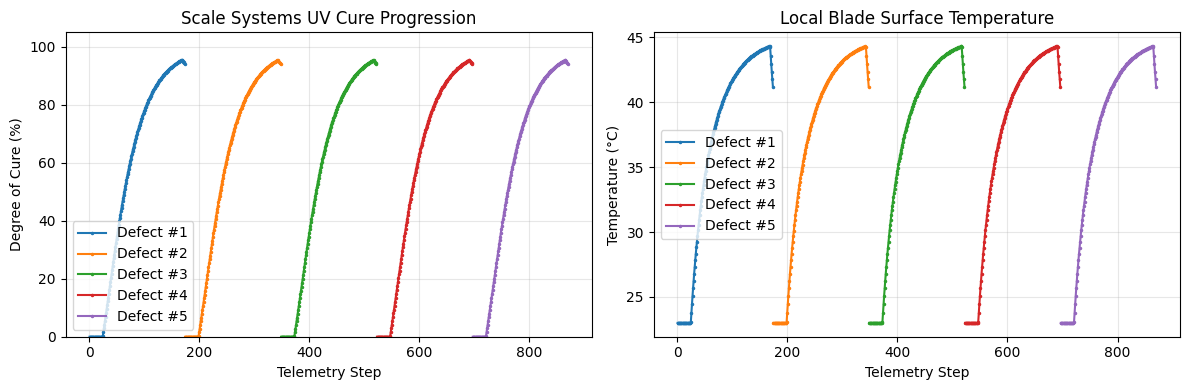

In [6]:
df_logs = pd.DataFrame([asdict(row) for row in telemetry_logs])
print("Total telemetry samples:", len(df_logs))
display(df_logs.groupby(["target_defect_id", "phase"]).agg(
    samples=("step_idx", "count"),
    max_cure=("cure_degree", "max"),
    max_temp_c=("surface_temp_c", "max"),
    peak_irradiance_mw_cm2=("uv_irradiance_mw_cm2", "max")
))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for did, grp in df_logs.groupby("target_defect_id"):
    ax1.plot(grp["step_idx"], grp["cure_degree"] * 100.0, marker=".", markersize=3, label=f"Defect #{did}")
ax1.set_title("Scale Systems UV Cure Progression")
ax1.set_xlabel("Telemetry Step")
ax1.set_ylabel("Degree of Cure (%)")
ax1.set_ylim(0, 105)
ax1.grid(True, alpha=0.3)
ax1.legend()

for did, grp in df_logs.groupby("target_defect_id"):
    ax2.plot(grp["step_idx"], grp["surface_temp_c"], marker=".", markersize=3, label=f"Defect #{did}")
ax2.set_title("Local Blade Surface Temperature")
ax2.set_xlabel("Telemetry Step")
ax2.set_ylabel("Temperature (°C)")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()